In [23]:
#api key: gAW2xBrYq11BrcCxKsDY0b

import requests
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

import math
import time
import os

from pathlib import Path
from getpass import getpass

from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

### Download data

In [24]:
# OpenAlex configuration
BASE_URL = "https://api.openalex.org"

API_KEY = "gAW2xBrYq11BrcCxKsDY0b"

# Sampling configuration
N_PER_FIELD = 5000       # Increase to 5000 later
START_YEAR = 2025
END_YEAR = 2025
BASE_SEED = 42

# Output directories
RAW_DIR = Path("data/raw")
PROCESSED_DIR = Path("data/processed")

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Configure requests with automatic retries
session = requests.Session()

retry_strategy = Retry(
    total=5,
    backoff_factor=1,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"],
    respect_retry_after_header=True
)

adapter = HTTPAdapter(max_retries=retry_strategy)

session.mount("https://", adapter)

print("Configuration complete.")

Configuration complete.


In [25]:
response = session.get(
    f"{BASE_URL}/fields",
    params={
        "per_page": 50,
        "api_key": API_KEY
    },
    timeout=60
)

response.raise_for_status()

field_results = response.json()["results"]

fields = [
    {
        "field_id": int(field["id"].split("/")[-1]),
        "field_name": field["display_name"]
    }
    for field in field_results
]

fields_df = pd.DataFrame(fields)

print(fields_df.to_string(index=False))
print("\nNumber of fields:", len(fields_df))

 field_id                                   field_name
       31                        Physics and Astronomy
       33                              Social Sciences
       27                                     Medicine
       12                          Arts and Humanities
       11         Agricultural and Biological Sciences
       22                                  Engineering
       17                             Computer Science
       23                        Environmental Science
       14          Business, Management and Accounting
       13 Biochemistry, Genetics and Molecular Biology
       19                 Earth and Planetary Sciences
       20          Economics, Econometrics and Finance
       25                            Materials Science
       16                                    Chemistry
       32                                   Psychology
       26                                  Mathematics
       28                                 Neuroscience
       24 

In [26]:
# Now retrieve the actual publications.

all_works = []

SELECT_FIELDS = (
    "id,display_name,publication_year,"
    "referenced_works,cited_by_count,type"
)

for field in fields:

    field_id = field["field_id"]
    field_name = field["field_name"]

    print(f"\nDownloading: {field_name}")

    params = {
        "filter": (
            f"primary_topic.field.id:{field_id},"
            f"from_publication_date:{START_YEAR}-01-01,"
            f"to_publication_date:{END_YEAR}-12-31,"
            "type:article"
        ),
        "sample": N_PER_FIELD,
        "seed": BASE_SEED + field_id,
        "per_page": 100,
        "api_key": API_KEY,
        "select": SELECT_FIELDS
    }

    field_works = []

    n_pages = math.ceil(N_PER_FIELD / 100)

    for page in range(1, n_pages + 1):

        params["page"] = page

        response = session.get(
            f"{BASE_URL}/works",
            params=params,
            timeout=60
        )

        response.raise_for_status()

        result = response.json()

        batch = result["results"]

        if not batch:
            break

        field_works.extend(batch)

        time.sleep(0.05)

    # Add field labels to each publication
    for work in field_works:

        work["field_id"] = field_id
        work["field_name"] = field_name

    all_works.extend(field_works)

    print(f"Retrieved {len(field_works)} publications.")

print("\nTotal publications:", len(all_works))


Downloading: Physics and Astronomy
Retrieved 5000 publications.

Downloading: Social Sciences
Retrieved 5000 publications.

Downloading: Medicine
Retrieved 5000 publications.

Downloading: Arts and Humanities
Retrieved 5000 publications.

Downloading: Agricultural and Biological Sciences
Retrieved 5000 publications.

Downloading: Engineering
Retrieved 5000 publications.

Downloading: Computer Science
Retrieved 5000 publications.

Downloading: Environmental Science
Retrieved 5000 publications.

Downloading: Business, Management and Accounting
Retrieved 5000 publications.

Downloading: Biochemistry, Genetics and Molecular Biology
Retrieved 5000 publications.

Downloading: Earth and Planetary Sciences
Retrieved 5000 publications.

Downloading: Economics, Econometrics and Finance
Retrieved 5000 publications.

Downloading: Materials Science
Retrieved 5000 publications.

Downloading: Chemistry
Retrieved 5000 publications.

Downloading: Psychology
Retrieved 5000 publications.

Downloading: M

### Convert to Dataframe

In [27]:
#convert to dataframe

records = []

for work in all_works:

    references = work.get("referenced_works") or []

    records.append({

        "work_id": work["id"],

        "title": work.get("display_name"),

        "year": work.get("publication_year"),

        "field_id": work["field_id"],

        "field": work["field_name"],

        "global_in_degree": work.get("cited_by_count") or 0,

        "global_out_degree": len(references),

        "referenced_works": references

    })

works_df = pd.DataFrame(records)

# Remove any accidental duplicate publications
works_df = works_df.drop_duplicates(
    subset="work_id"
).reset_index(drop=True)

print(works_df.head())
print("\nPublications per field:")
print(works_df["field"].value_counts())

                            work_id  \
0  https://openalex.org/W4416855475   
1  https://openalex.org/W4408737422   
2  https://openalex.org/W4414116340   
3  https://openalex.org/W4415437515   
4  https://openalex.org/W7104250117   

                                               title  year  field_id  \
0  Superdeformed $$\mathbb{C}\mathbb{P}$$ σ-Model...  2025        31   
1  Unified Simulation Platform for Optical Tweeze...  2025        31   
2  Review of recent observations of magnetic hole...  2025        31   
3  Exact solution of the three-dimensional (3D) Z...  2025        31   
4  FCC-ee optics tuning studies with pyAT and Xsuite  2025        31   

                   field  global_in_degree  global_out_degree  \
0  Physics and Astronomy                 2                 19   
1  Physics and Astronomy                 8                 36   
2  Physics and Astronomy                 2                 52   
3  Physics and Astronomy                11                 90   
4  Phys

In [28]:
#save raw sample
works_df.to_parquet(
    RAW_DIR / "sampled_works.parquet",
    index=False
)

print("Publication sample saved.")

Publication sample saved.


### Construct Citation Network

In [29]:
#construct citation network

field_graphs = {}

edge_records = []

for field in fields:

    field_name = field["field_name"]

    print("Constructing graph:", field_name)

    # Select publications belonging to this field
    subset = works_df[
        works_df["field"] == field_name
    ]

    # Set of sampled publication IDs
    work_ids = set(subset["work_id"])

    # Initialize directed graph
    G = nx.DiGraph()

    # Add all sampled publications as nodes
    G.add_nodes_from(work_ids)

    # Add citation edges
    for row in subset.itertuples(index=False):

        citing_work = row.work_id

        for cited_work in row.referenced_works:

            if cited_work in work_ids:

                if citing_work != cited_work:

                    G.add_edge(
                        citing_work,
                        cited_work
                    )

                    edge_records.append({
                        "field": field_name,
                        "citing_work": citing_work,
                        "cited_work": cited_work
                    })

    field_graphs[field_name] = G

    print(
        f"Nodes: {G.number_of_nodes():,} | "
        f"Edges: {G.number_of_edges():,}"
    )

print("\nFinished constructing all networks.")

Constructing graph: Physics and Astronomy
Nodes: 5,000 | Edges: 171
Constructing graph: Social Sciences
Nodes: 5,000 | Edges: 7
Constructing graph: Medicine
Nodes: 5,000 | Edges: 6
Constructing graph: Arts and Humanities
Nodes: 5,000 | Edges: 0
Constructing graph: Agricultural and Biological Sciences
Nodes: 5,000 | Edges: 21
Constructing graph: Engineering
Nodes: 5,000 | Edges: 30
Constructing graph: Computer Science
Nodes: 5,000 | Edges: 22
Constructing graph: Environmental Science
Nodes: 5,000 | Edges: 48
Constructing graph: Business, Management and Accounting
Nodes: 5,000 | Edges: 18
Constructing graph: Biochemistry, Genetics and Molecular Biology
Nodes: 5,000 | Edges: 41
Constructing graph: Earth and Planetary Sciences
Nodes: 5,000 | Edges: 109
Constructing graph: Economics, Econometrics and Finance
Nodes: 5,000 | Edges: 31
Constructing graph: Materials Science
Nodes: 5,000 | Edges: 115
Constructing graph: Chemistry
Nodes: 5,000 | Edges: 155
Constructing graph: Psychology
Nodes: 5,

In [30]:
# save edges 
edges_df = pd.DataFrame(edge_records)

edges_df.to_parquet(
    RAW_DIR / "citation_edges.parquet",
    index=False
)

print("Citation edge data saved.")

Citation edge data saved.


### Network Statistics Calculations

In [31]:
#network statistics

network_stats = []

def summarize_scores(scores, prefix):

    values = np.array(
        list(scores.values()),
        dtype=float
    )

    return {
        f"{prefix}_median": np.median(values),
        f"{prefix}_p95": np.quantile(values, 0.95),
        f"{prefix}_max": np.max(values)
    }


for field_name, G in field_graphs.items():

    print("Analyzing:", field_name)

    subset = works_df[
        works_df["field"] == field_name
    ]

    n = G.number_of_nodes()
    m = G.number_of_edges()

    # Full-record degree statistics
    global_in = subset["global_in_degree"]
    global_out = subset["global_out_degree"]

    # Within-sample degrees
    in_degrees = dict(G.in_degree())
    out_degrees = dict(G.out_degree())

    in_values = np.array(list(in_degrees.values()))
    out_values = np.array(list(out_degrees.values()))

    # Undirected projection for clustering
    UG = G.to_undirected()

    if n > 0:

        avg_clustering = nx.average_clustering(UG)

        transitivity = nx.transitivity(UG)

        isolates = len(list(nx.isolates(G)))

        weak_components = list(
            nx.weakly_connected_components(G)
        )

        strong_components = list(
            nx.strongly_connected_components(G)
        )

        largest_wcc = max(
            (len(c) for c in weak_components),
            default=0
        )

        largest_scc = max(
            (len(c) for c in strong_components),
            default=0
        )

    else:

        avg_clustering = np.nan
        transitivity = np.nan
        isolates = 0
        weak_components = []
        strong_components = []
        largest_wcc = 0
        largest_scc = 0

    # Fraction of recorded references that remain inside
    # the sampled field network
    total_references = global_out.sum()

    internal_edge_fraction = (
        m / total_references
        if total_references > 0
        else np.nan
    )

    # Calculate centrality measures
    if n > 1 and m > 0:

        # Approximate betweenness using 100 pivot nodes
        betweenness = nx.betweenness_centrality(
            G,
            k=min(100, n - 1),
            normalized=True,
            seed=BASE_SEED
        )

        # PageRank
        pagerank = nx.pagerank(
            G,
            alpha=0.85,
            max_iter=200,
            tol=1e-6
        )

        # HITS: hubs and authorities
        try:

            hubs, authorities = nx.hits(
                G,
                max_iter=500,
                tol=1e-8,
                normalized=True
            )

        except (nx.PowerIterationFailedConvergence, ZeroDivisionError):

            hubs = {}
            authorities = {}

    else:

        betweenness = {node: 0 for node in G.nodes()}

        pagerank = (
            {node: 1 / n for node in G.nodes()}
            if n > 0 else {}
        )

        hubs = {}
        authorities = {}

    # Compile statistics
    stats = {

        "field": field_name,

        "n_nodes": n,

        "n_edges": m,

        "density": nx.density(G),

        # Full-record OpenAlex degrees
        "global_mean_in_degree": global_in.mean(),

        "global_median_in_degree": global_in.median(),

        "global_mean_out_degree": global_out.mean(),

        "global_median_out_degree": global_out.median(),

        # Sample-induced network degrees
        "sample_mean_in_degree": in_values.mean() if n else np.nan,

        "sample_mean_out_degree": out_values.mean() if n else np.nan,

        "sample_median_in_degree": np.median(in_values) if n else np.nan,

        "sample_median_out_degree": np.median(out_values) if n else np.nan,

        "isolates": isolates,

        "isolate_fraction": isolates / n if n else np.nan,

        "weak_component_count": len(weak_components),

        "strong_component_count": len(strong_components),

        "largest_wcc_fraction": largest_wcc / n if n else np.nan,

        "largest_scc_fraction": largest_scc / n if n else np.nan,

        "average_clustering_undirected": avg_clustering,

        "transitivity_undirected": transitivity,

        "internal_edge_fraction": internal_edge_fraction

    }

    # Add centrality summaries
    stats.update(
        summarize_scores(betweenness, "betweenness")
    )

    stats.update(
        summarize_scores(pagerank, "pagerank")
    )

    if hubs:

        stats.update(
            summarize_scores(hubs, "hub")
        )

        stats.update(
            summarize_scores(authorities, "authority")
        )

    else:

        stats.update({
            "hub_median": np.nan,
            "hub_p95": np.nan,
            "hub_max": np.nan,
            "authority_median": np.nan,
            "authority_p95": np.nan,
            "authority_max": np.nan
        })

    network_stats.append(stats)


# Convert to DataFrame
network_stats_df = pd.DataFrame(network_stats)

network_stats_df = network_stats_df.sort_values(
    "field"
).reset_index(drop=True)

print(network_stats_df.to_string(index=False))

Analyzing: Physics and Astronomy
Analyzing: Social Sciences
Analyzing: Medicine
Analyzing: Arts and Humanities
Analyzing: Agricultural and Biological Sciences
Analyzing: Engineering
Analyzing: Computer Science
Analyzing: Environmental Science
Analyzing: Business, Management and Accounting
Analyzing: Biochemistry, Genetics and Molecular Biology
Analyzing: Earth and Planetary Sciences
Analyzing: Economics, Econometrics and Finance
Analyzing: Materials Science
Analyzing: Chemistry
Analyzing: Psychology
Analyzing: Mathematics
Analyzing: Neuroscience
Analyzing: Immunology and Microbiology
Analyzing: Health Professions
Analyzing: Energy
Analyzing: Decision Sciences
Analyzing: Nursing
Analyzing: Dentistry
Analyzing: Pharmacology, Toxicology and Pharmaceutics
Analyzing: Chemical Engineering
Analyzing: Veterinary
                                       field  n_nodes  n_edges      density  global_mean_in_degree  global_median_in_degree  global_mean_out_degree  global_median_out_degree  sample_me

In [32]:
# save statistics

network_stats_df.to_csv(
    PROCESSED_DIR / "field_network_statistics.csv",
    index=False
)

print("Network statistics saved to CSV.")

Network statistics saved to CSV.


### Plot Degree Distributions

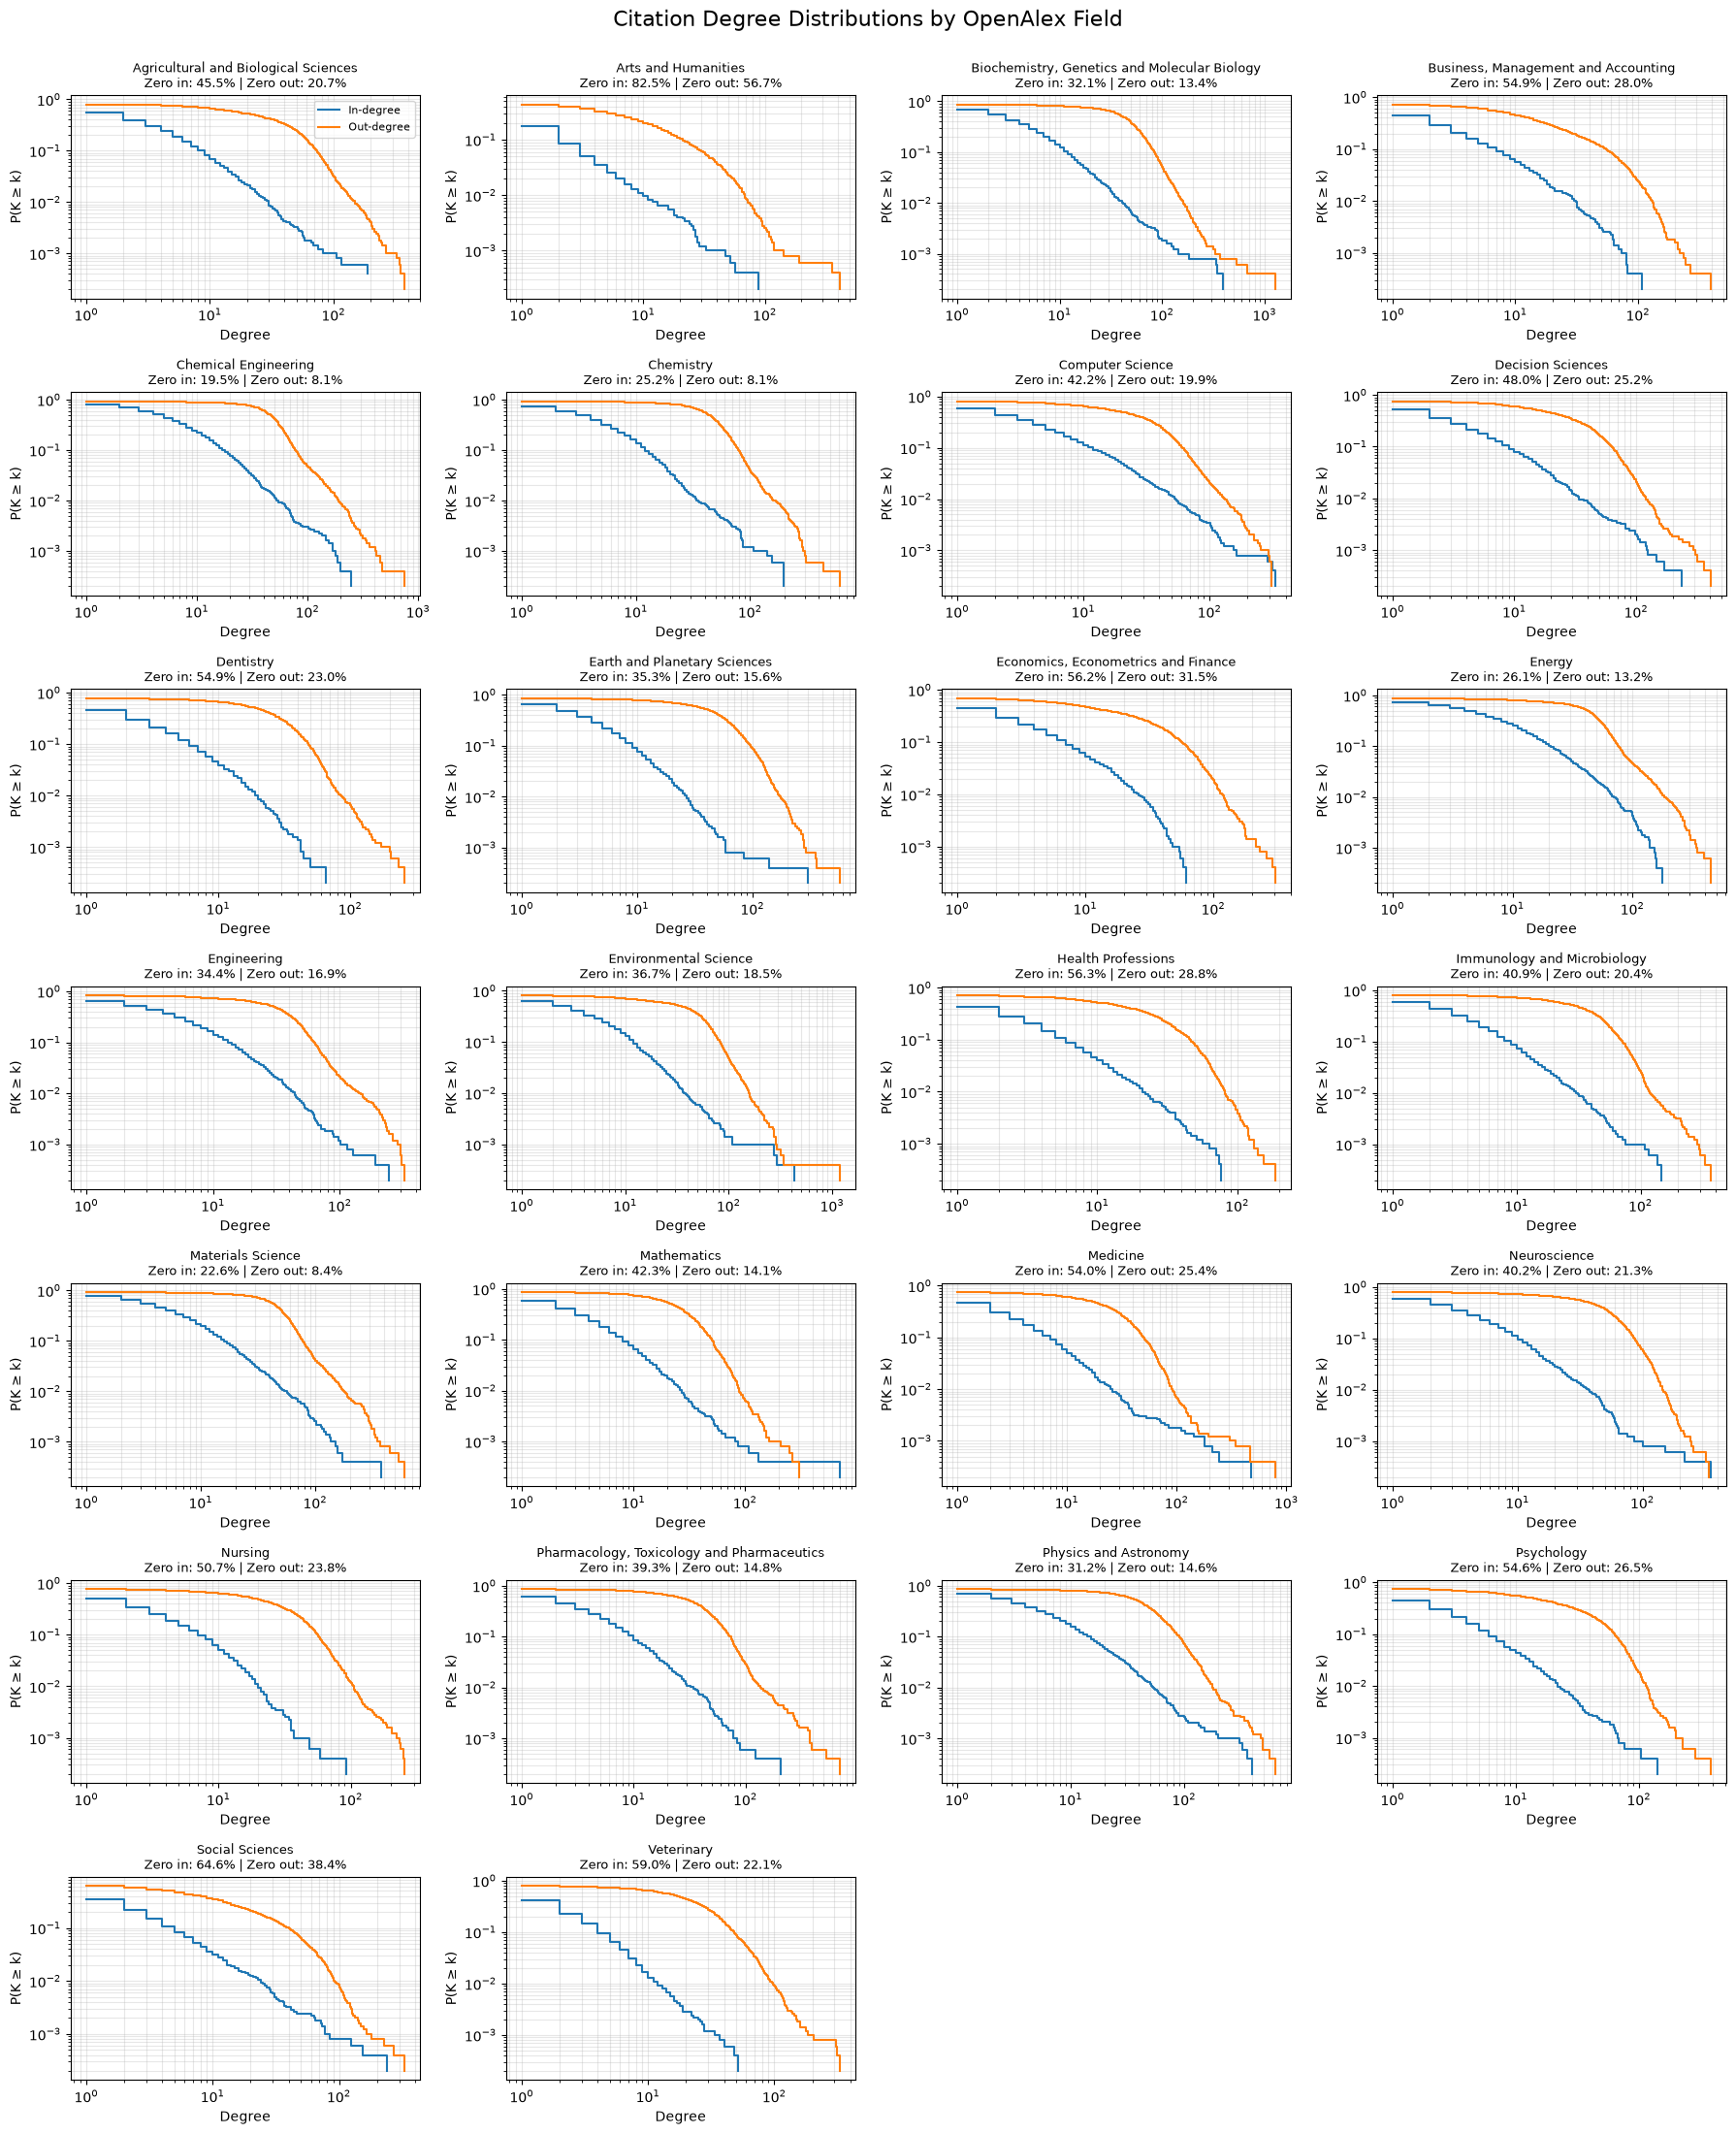

In [33]:
def plot_ccdf(ax, values, label):

    values = np.asarray(values, dtype=int)

    positive_values = values[values > 0]

    if len(positive_values) == 0:
        return

    # Unique degree values and their frequencies
    x, counts = np.unique(
        positive_values,
        return_counts=True
    )

    # Complementary cumulative distribution
    y = np.cumsum(counts[::-1])[::-1] / len(values)

    ax.step(
        x,
        y,
        where="post",
        label=label
    )


# Plot configuration
field_names = sorted(works_df["field"].unique())

ncols = 4
nrows = math.ceil(len(field_names) / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(18, 3.2 * nrows)
)

axes = axes.flatten()


for i, field_name in enumerate(field_names):

    ax = axes[i]

    subset = works_df[
        works_df["field"] == field_name
    ]

    in_degree = subset["global_in_degree"]

    out_degree = subset["global_out_degree"]

    plot_ccdf(
        ax,
        in_degree,
        "In-degree"
    )

    plot_ccdf(
        ax,
        out_degree,
        "Out-degree"
    )

    ax.set_xscale("log")
    ax.set_yscale("log")

    zero_in = (in_degree == 0).mean()
    zero_out = (out_degree == 0).mean()

    ax.set_title(
        f"{field_name}\n"
        f"Zero in: {zero_in:.1%} | "
        f"Zero out: {zero_out:.1%}",
        fontsize=9
    )

    ax.set_xlabel("Degree")
    ax.set_ylabel("P(K ≥ k)")

    ax.grid(
        True,
        which="both",
        alpha=0.3
    )

    if i == 0:
        ax.legend(fontsize=8)


# Hide unused panels
for j in range(len(field_names), len(axes)):
    axes[j].set_visible(False)


fig.suptitle(
    "Citation Degree Distributions by OpenAlex Field",
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.98])

plt.savefig(
    PROCESSED_DIR / "degree_distributions_by_field.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [34]:
diagnostics = network_stats_df[
    [
        "field",
        "n_nodes",
        "n_edges",
        "density",
        "internal_edge_fraction",
        "isolate_fraction",
        "largest_wcc_fraction"
    ]
].sort_values("internal_edge_fraction")

print(diagnostics.to_string(index=False))

                                       field  n_nodes  n_edges      density  internal_edge_fraction  isolate_fraction  largest_wcc_fraction
                         Arts and Humanities     5000        0 0.000000e+00                0.000000            1.0000                0.0002
                                    Medicine     5000        6 2.400480e-07                0.000057            0.9976                0.0004
                             Social Sciences     5000        7 2.800560e-07                0.000112            0.9972                0.0004
        Agricultural and Biological Sciences     5000       21 8.401680e-07                0.000137            0.9918                0.0006
                            Computer Science     5000       22 8.801760e-07                0.000167            0.9914                0.0006
                                  Psychology     5000       21 8.401680e-07                0.000183            0.9922                0.0006
Biochemistry, Geneti